# Un premier modèle pommes_craft, pas à pas

Vous allez construire, en huit étapes, le modèle d'une petite zone qui consomme 1 MW toute l'année et achète son
électricité au prix horaire français de 2030. Vous y ajouterez un parc solaire dont le modèle choisit lui-même la
taille, puis une turbine à gaz déjà construite ; vous lirez ensuite la solution et les prix que le modèle en déduit.
Pour finir, vous relancerez le même modèle sous quatre futurs de prix, et vous verrez que sa décision ne suit pas le
prix moyen.

**Mode d'emploi.** Exécutez les cellules dans l'ordre, de haut en bas (Maj + Entrée). Chaque étape finit par une
**valeur attendue** : comparez-la à ce que vous obtenez. Un écart au centime près est normal ; un écart d'un pour cent
ne l'est pas, il signale une erreur de saisie ou une autre version des paquets. Comptez une heure ; chaque résolution
prend une à deux secondes.

**La cellule d'installation.** En local, ouvrez ce notebook depuis le dossier `premier_modele/` ou depuis la racine du
dépôt, avec le noyau du venv du dépôt (`.venv`) : la cellule n'installe rien, elle trouve le dépôt et affiche les
versions des paquets. Elles doivent être celles du dépôt : pommes 0.11.0, pommes-craft 0.6.0, linopy 0.10.1 et
highspy 1.15.1 (le solveur HiGHS).

Sur Google Colab, la cellule clone le dépôt et installe ces paquets : 2 à 3 minutes, presque sans affichage, ce n'est
pas bloqué. Elle s'arrête ensuite volontairement sur le message `RedemarrezLaSession` : Colab a déjà chargé ses propres
versions de numpy et pandas, et seul un redémarrage les remplace. Faites alors Exécution › Redémarrer la session, puis
relancez cette cellule, et seulement elle ; elle n'installe plus rien et vous pouvez continuer. pip signale au passage
des conflits avec des paquets de Colab (`google-colab requires pandas==…`) : ils sont sans effet ici.

In [1]:
import sys
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

VERSIONS = {"pommes": "0.11.0", "pommes-craft": "0.6.0", "linopy": "0.10.1", "highspy": "1.15.1"}


def versions_du_depot() -> bool:
    """Vrai si les paquets installés sont ceux de requirements.txt (les valeurs attendues en dépendent)."""
    try:
        return all(version(nom) == v for nom, v in VERSIONS.items())
    except PackageNotFoundError:
        return False


class RedemarrezLaSession(Exception):
    """Colab : les paquets sont installés, mais la session garde en mémoire les anciens numpy et pandas."""


if "google.colab" in sys.modules:                     # sur Colab : cloner, installer, redémarrer une fois
    CLONE = Path("/content/pommes-case-studies")
    if not CLONE.exists():
        !git clone https://git.persee.minesparis.psl.eu/energy-alternatives/pommes_studies/pommes-case-studies {CLONE}
    %cd {CLONE}
    if not versions_du_depot():
        !python --version
        !pip install -q -r requirements.txt
        raise RedemarrezLaSession("Installation finie. Exécution › Redémarrer la session, "
                                  "puis relancez cette cellule (et seulement elle).")

ICI = Path.cwd() if Path.cwd().name == "premier_modele" else Path.cwd() / "premier_modele"
RACINE = ICI.parent                                   # la racine du dépôt des cas
if not (RACINE / "pommes_cases").is_dir():
    raise FileNotFoundError(f"pas de pommes_cases/ sous {RACINE} : ouvrez ce notebook depuis premier_modele/ "
                            "ou depuis la racine du dépôt pommes-case-studies")
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))
print("dépôt :", RACINE.name, "· Python", sys.version.split()[0])
print(" · ".join(f"{nom} {version(nom)}" for nom in VERSIONS))
if not versions_du_depot():
    print("Attention : ce ne sont pas les versions du dépôt", VERSIONS, ": les valeurs attendues peuvent bouger.")

dépôt : pommes-case-studies · Python 3.12.8
pommes 0.11.0 · pommes-craft 0.6.0 · linopy 0.10.1 · highspy 1.15.1


**Valeur attendue** : `pommes 0.11.0 · pommes-craft 0.6.0 · linopy 0.10.1 · highspy 1.15.1`, sans ligne « Attention ».

## Étape 1 — Lire un prix horaire 2030

La première hypothèse du modèle est le prix auquel la zone achète son électricité. Les prix du dépôt sortent de
modèles de marché, pas de la bourse. On prend celui du TYNDP 2026, le plan décennal des gestionnaires de réseau
européens (ENTSO-E), scénario NT+, pour la France en 2030.

La fonction `load_prices` lit ce jeu de prix et renvoie un tableau de 8 760 lignes, une par heure, avec les colonnes
dont le réseau aura besoin à l'étape 2 (`hour`, `year_op`, `import_price`, `export_price`). Le TYNDP 2026 publie trois
années météo, pondérées ; par défaut, on prend celle de plus grand poids, WS003.

In [2]:
from pommes_cases.prices import load_prices, price_sets

p = load_prices("tyndp2026", "NT+", "FR", 2030)
print(p.shape, p.columns)
print(price_sets()["tyndp2026"].default_meteo(2030))
prix = p["import_price"]
print(f"moyenne {prix.mean():.2f} €/MWh, min {prix.min():.2f}, max {prix.max():.2f}, somme {prix.sum():,.0f} €")

(8760, 4) ['hour', 'year_op', 'import_price', 'export_price']
WS003
moyenne 57.50 €/MWh, min 0.00, max 350.00, somme 503,710 €


La moyenne, 57,50 €/MWh, est ce que paie un consommateur plat, qui tire 1 MW toutes les heures : sa facture de
l'année est la somme des 8 760 prix, 503 710 €. Elle ne dit rien de la forme de la série.

La **monotone** range les 8 760 prix du plus cher au moins cher. L'aire sous la courbe est la facture du consommateur
plat. À gauche, les heures rares et chères ; à droite, le plateau des heures bon marché, jusqu'aux heures à prix nul.

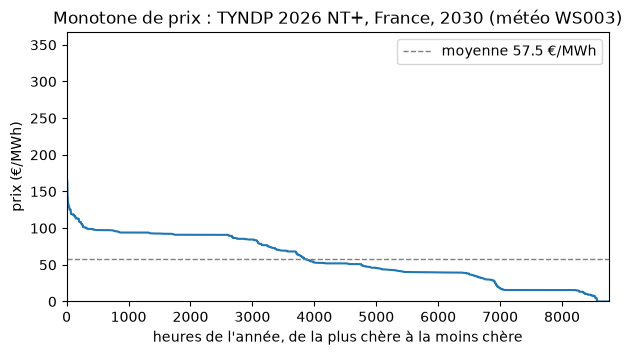

heures à 0 €/MWh exactement : 8
heures sous 0,5 €/MWh : 196
plafond de la série (son maximum) : 350.00 €/MWh, atteint 1 heure(s)
heures à 1 000 €/MWh ou plus : 0


In [3]:
import matplotlib.pyplot as plt
import numpy as np

monotone = np.sort(prix.to_numpy())[::-1]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, 8761), monotone, lw=1.5)
ax.axhline(prix.mean(), color="grey", ls="--", lw=1, label=f"moyenne {prix.mean():.1f} €/MWh")
ax.set(xlabel="heures de l'année, de la plus chère à la moins chère", ylabel="prix (€/MWh)", xlim=(0, 8760),
       ylim=(0, None), title="Monotone de prix : TYNDP 2026 NT+, France, 2030 (météo WS003)")
ax.legend()
plt.show()

print(f"heures à 0 €/MWh exactement : {(prix == 0).sum()}")
print(f"heures sous 0,5 €/MWh : {(prix < 0.5).sum()}")
print(f"plafond de la série (son maximum) : {prix.max():.2f} €/MWh, atteint {(prix == prix.max()).sum()} heure(s)")
print(f"heures à 1 000 €/MWh ou plus : {(prix >= 1000).sum()}")

Un prix de modèle tombe à 0 €/MWh quand la production solaire et éolienne dépasse ce que le système peut prendre ; il
ne descend jamais en dessous, alors que le marché réel connaît des heures négatives. Ici, 8 heures sont à 0 €/MWh
exactement, et 196 sous 0,5 €/MWh : la plupart de ces heures valent 0,01 à 0,05 €/MWh, nulles en pratique.

Le plafond de cette série, son maximum, est de 350 €/MWh, atteint une seule heure. Aucune heure n'atteint
1 000 €/MWh, le seuil au-delà duquel le dépôt compte une heure de défaillance (une heure où la demande n'est pas
servie, payée au coût de l'énergie non servie). D'autres séries en ont : tout ce qui ne vaut qu'à la pointe en dépend.

**Valeur attendue** : `(8760, 4)`, année météo WS003 ; moyenne 57,50 €/MWh, min 0,00, max 350,00, somme 503 710 € ;
8 heures à 0 €/MWh exactement, 196 sous 0,5 €/MWh ; plafond 350 €/MWh atteint 1 heure ; 0 heure à 1 000 €/MWh ou plus.

## Étape 2 — Une zone, une demande, le réseau

On écrit maintenant le modèle le plus simple : une zone, sa demande, et le réseau qui la sert. Un modèle pommes_craft
(`EnergyModel`) porte quatre indices de temps : l'heure (`hour`, 8 760 valeurs), l'année d'exploitation (`year_op`,
2030), l'année d'investissement (`year_inv`, 2030) et l'année de sortie des installations (`year_dec`, 2055). pommes
n'ouvre une capacité que si l'écart entre sortie et investissement égale sa durée de vie : 25 ans ici.

La fonction `modele_de_base` ajoute un composant par ligne :

- les hypothèses économiques (`EconomicHypothesis`) : un taux d'actualisation nul ;
- le pas de temps (`TimeStepManager`) : un pas vaut une heure, l'année 8 760 heures ;
- la zone (`Area`) et sa consommation (`Demand`) : 1 MW toute l'année ;
- le réseau (`NetImport`) : il vend à la zone au prix horaire de l'étape 1 et ne lui rachète rien
  (`max_yearly_energy_export=0.0`) ;
- le délestage, couper une partie de la demande (`LoadShedding`), et l'écrêtement, jeter un surplus (`Spillage`) :
  leur capacité nulle les interdit. L'étape 5 montre pourquoi il faut quand même les écrire.

Elle renvoie le modèle et sa zone : les étapes suivantes y ajouteront d'autres composants, dans un bloc
`with m.context():`.

In [4]:
import logging

import polars as pl
from pommes_craft import (Area, ConversionTechnology, Demand, EconomicHypothesis, EnergyModel, LoadShedding,
                          NetImport, Spillage, TimeStepManager)

logging.getLogger().setLevel(logging.ERROR)  # tait l'écho des paramètres laissés à leur valeur par défaut


def modele_de_base(nom, delestage="interdit"):
    """delestage : "interdit" (capacité 0), "aucun" (pas de composant) ou un coût en €/MWh."""
    m = EnergyModel(name=nom, hours=list(range(8760)), year_ops=[2030], year_invs=[2030], year_decs=[2055],
                    modes=[], resources=["electricity"], solver_name="highs",
                    solver_options={"output_flag": False})
    with m.context():
        EconomicHypothesis("eco", discount_rate=0.0, year_ref=2030, planning_step=1)
        TimeStepManager("pas", time_step_duration=1.0, operation_year_duration=8760.0)
        zone = Area("FR")
        zone.add_component(Demand(name="demande", resource="electricity",
                                  demand=pl.DataFrame({"hour": range(8760), "year_op": 2030, "demand": 1.0})))
        if delestage == "interdit":
            zone.add_component(LoadShedding(name="delestage", resource="electricity", max_capacity=0.0))
        elif delestage != "aucun":
            zone.add_component(LoadShedding(name="delestage", resource="electricity", cost=float(delestage)))
        zone.add_component(Spillage(name="ecretement", resource="electricity", max_capacity=0.0))
        zone.add_component(NetImport(name="reseau", resource="electricity",
                                     import_price=p.select("hour", "year_op", "import_price"),
                                     max_yearly_energy_export=0.0))
    return m, zone


m, zone = modele_de_base("reseau_seul")
m.run(store_linopy_model=True)
print(f"coût total {m.linopy_model.objective.value:,.2f} €, somme des prix {prix.sum():,.2f} €")

coût total 503,709.84 €, somme des prix 503,709.84 €


Le coût total vaut la somme des 8 760 prix : 1 MW pendant une heure, c'est 1 MWh payé au prix de cette heure. Ce
premier modèle ne choisit rien, puisqu'il n'a qu'une façon de servir la demande ; il vérifie que tout est bien branché.

La résolution n'affiche rien d'autre : pommes_craft envoie le journal du solveur dans un fichier temporaire. La
bibliothèque qui écrit le programme linéaire (linopy) émet de nombreux avertissements sans conséquence ; l'import de
`pommes_cases` à l'étape 1 les tait.

**Valeur attendue** : coût total 503 709,84 €, égal à la somme des prix.

## Étape 3 — Un PV dont pommes choisit la taille

On ajoute un parc solaire photovoltaïque (PV) dont pommes choisit la capacité. Il produit de l'électricité
(`factor={"electricity": 1.0}`) sous un plafond horaire, son facteur de charge (`availability`) : la part de sa
capacité qu'il peut produire à chaque heure, selon le soleil. On prend celui de l'année météo WS003, la même que pour
les prix.

Le PV coûte 600 000 € par MW installé, dure 25 ans, et se finance au taux de 4 %. Pour comparer cet investissement aux
achats d'une année, on l'**annualise** : l'annuité est la somme constante, payée chaque année pendant 25 ans, qui
rembourse l'investissement et ses intérêts.

In [5]:
investissement, taux, duree = 600_000.0, 0.04, 25        # €/MW, taux annuel, années
annuite = investissement * taux / (1 - (1 + taux) ** -duree)
print(f"annuité du PV : {annuite:,.0f} €/MW/an")

annuité du PV : 38,407 €/MW/an


pommes fait ce calcul lui-même, à partir du coût d'investissement (`invest_cost`), de la durée de vie (`life_span`) et
du taux (`finance_rate`). Il choisit la capacité qui rend minimale la somme de l'annuité et des achats de l'année.

In [6]:
from pommes_cases.meteo import availability, load_meteo

pv_dispo = availability(load_meteo("FR", 2030), "pv")
print(f"facteur de charge PV moyen {pv_dispo['availability'].mean():.3f}")


def pv():
    return ConversionTechnology(name="pv", factor={"electricity": 1.0}, availability=pv_dispo,
                                invest_cost=600_000.0, life_span=25, finance_rate=0.04)


m, zone = modele_de_base("reseau_pv")
with m.context():
    zone.add_component(pv())
m.run(store_linopy_model=True)
print(m.get_results("planning", "power_capacity").select("name", "value"))
print(f"coût total {m.linopy_model.objective.value:,.2f} €")

facteur de charge PV moyen 0.138


shape: (1, 2)
┌──────┬──────────┐
│ name ┆ value    │
│ ---  ┆ ---      │
│ str  ┆ f64      │
╞══════╪══════════╡
│ pv   ┆ 1.647446 │
└──────┴──────────┘
coût total 500,124.82 €


pommes construit 1,647 MW de PV pour 1 MW de demande. Au-delà, le surplus de midi ne trouverait pas preneur, puisque
la zone ne revend rien au réseau. Le coût total baisse de 3 585 € par rapport à l'étape 2.

**Valeur attendue** : annuité 38 407 €/MW/an ; facteur de charge PV moyen 0,138 ; capacité PV 1,647446 MW ; coût total
500 124,82 €.

**À vous.** Passez le coût d'investissement du PV à 300 000 €/MW. Avant de lancer, écrivez votre prédiction : la
capacité construite monte-t-elle ou baisse-t-elle ? Et le coût total ? Enlevez ensuite les `#` de la cellule suivante
et lancez-la.

In [7]:
# def pv_moins_cher():
#     return ConversionTechnology(name="pv", factor={"electricity": 1.0}, availability=pv_dispo,
#                                 invest_cost=300_000.0, life_span=25, finance_rate=0.04)
#
#
# m_essai, zone_essai = modele_de_base("reseau_pv_300k")
# with m_essai.context():
#     zone_essai.add_component(pv_moins_cher())
# m_essai.run(store_linopy_model=True)
# print(m_essai.get_results("planning", "power_capacity").select("name", "value"))
# print(f"coût total {m_essai.linopy_model.objective.value:,.2f} €")

## Étape 4 — Une turbine à gaz existante

Une turbine à gaz produit à 110 €/MWh, son coût variable (surtout le gaz et le CO₂). Elle n'évite donc un achat
qu'aux heures où le prix dépasse 110 €/MWh. Une turbine neuve se paierait-elle ?

In [8]:
gain = (prix - 110.0).clip(lower_bound=0.0).sum()          # €/MW/an : écarts de prix au-dessus de 110 €/MWh
annuite_turbine = 500_000.0 * 0.04 / (1 - 1.04 ** -25)      # 500 000 €/MW, 25 ans, 4 %
print(f"gain d'un MW de turbine {gain:,.0f} €/an, annuité d'une turbine neuve {annuite_turbine:,.0f} €/MW/an")

gain d'un MW de turbine 2,843 €/an, annuité d'une turbine neuve 32,006 €/MW/an


Non : une turbine neuve ne gagnerait pas le dixième de son annuité. On modélise donc une turbine **déjà construite**,
sans investissement (`invest_cost=0.0`), à 110 €/MWh de coût variable (`variable_cost`). Sa capacité est imposée à 1 MW
(`power_capacity_investment_min` et `power_capacity_investment_max` à 1,0).

In [9]:
def turbine():
    return ConversionTechnology(name="turbine_gaz", factor={"electricity": 1.0}, variable_cost=110.0,
                                invest_cost=0.0, life_span=25,
                                power_capacity_investment_min=1.0, power_capacity_investment_max=1.0)


m, zone = modele_de_base("reseau_pv_turbine")
with m.context():
    zone.add_component(pv())
    zone.add_component(turbine())
m.run(store_linopy_model=True, store_pommes_parameters=True)
print(f"coût total {m.linopy_model.objective.value:,.2f} €")
print(f"heures où le prix dépasse 110 €/MWh : {(prix > 110).sum()}")

coût total 497,405.29 €
heures où le prix dépasse 110 €/MWh : 199


Le coût baisse encore de 2 720 € : la turbine remplace les achats aux heures où le prix dépasse 110 €/MWh. L'option
`store_pommes_parameters=True` garde les paramètres du modèle, dont l'étape 7 aura besoin. Ce modèle `m` sert de
référence jusqu'à l'étape 7.

**Valeur attendue** : gain 2 843 €/an contre une annuité de 32 006 €/MW/an ; coût total 497 405,29 € ; 199 heures au-dessus
de 110 €/MWh.

## Étape 5 — Le piège du délestage gratuit

Pourquoi écrire, à l'étape 2, un délestage interdit ? Parce que, sans composant de délestage (`LoadShedding`), pommes
0.11.0 en ajoute un de lui-même, gratuit et illimité. Le modèle trouve alors une solution à coût nul : ne rien
produire, ne rien acheter, et couper toute la demande.

In [10]:
m_piege, zone = modele_de_base("sans_delestage", delestage="aucun")
with m_piege.context():
    zone.add_component(pv())
    zone.add_component(turbine())
m_piege.run(store_linopy_model=True)
sol = m_piege.linopy_model.solution
print(f"coût total {m_piege.linopy_model.objective.value:,.2f} €, "
      f"délestage {float(sol['operation_load_shedding_power'].sum()):,.0f} MWh")

coût total 0.00 €, délestage 8,760 MWh


Coût nul, 8 760 MWh délestés : toute la demande de l'année est coupée. Un modèle qui coûte 0 € doit toujours faire
chercher ce piège.

Deux remèdes : la capacité nulle de l'étape 2, ou un coût de défaillance explicite, le prix payé pour chaque MWh non
servi. À 3 000 €/MWh, le délestage ne sert jamais ici. Sans coût donné (`cost`), pommes_craft 0.6.0 met
1 000 €/MWh par défaut.

In [11]:
m_vdl, zone = modele_de_base("delestage_3000", delestage=3000.0)
with m_vdl.context():
    zone.add_component(pv())
    zone.add_component(turbine())
m_vdl.run(store_linopy_model=True)
print(f"coût total {m_vdl.linopy_model.objective.value:,.2f} €, "
      f"délestage {float(m_vdl.linopy_model.solution['operation_load_shedding_power'].sum()):,.0f} MWh")

coût total 497,405.29 €, délestage 0 MWh


**Valeur attendue** : sans délestage écrit, coût total 0,00 € et 8 760 MWh délestés ; avec un délestage à 3 000 €/MWh,
coût total 497 405,29 € (celui de l'étape 4) et 0 MWh délestés.

## Étape 6 — Lire la solution

On revient au modèle `m` de l'étape 4. Deux façons de lire sa solution : `get_results` rassemble une grandeur pour
tous les composants d'un type, dans un tableau ; `m.linopy_model.solution` donne les variables brutes de pommes,
nommées par module puis par grandeur (par exemple `operation_net_import_import`, l'import du réseau heure par heure).

In [12]:
sol = m.linopy_model.solution
prod = m.get_results("operation", "power", component_classes=[ConversionTechnology])
print(prod.group_by("name").agg(pl.col("value").sum().alias("MWh")).sort("name"))
print(f"import {float(sol['operation_net_import_import'].sum()):,.0f} MWh")
for v in ("planning_conversion_costs", "operation_conversion_costs", "operation_net_import_costs"):
    print(f"{v:32s} {float(sol[v].sum()):>12,.0f} €")
cap = float(sol["planning_conversion_power_capacity"].sel(conversion_tech="pv").sum())
print(f"PV : {cap:.3f} MW, potentiel {cap * pv_dispo['availability'].sum():,.0f} MWh")

shape: (2, 2)
┌─────────────┬─────────────┐
│ name        ┆ MWh         │
│ ---         ┆ ---         │
│ str         ┆ f64         │
╞═════════════╪═════════════╡
│ pv          ┆ 1959.398702 │
│ turbine_gaz ┆ 181.579901  │
└─────────────┴─────────────┘
import 6,619 MWh
planning_conversion_costs              63,274 €
operation_conversion_costs             19,974 €
operation_net_import_costs            414,158 €
PV : 1.647 MW, potentiel 1,991 MWh


Le bilan est fermé : 1 959 MWh de PV, 182 MWh de turbine et 6 619 MWh d'import font les 8 760 MWh de la demande. Le PV
aurait pu produire 1 991 MWh : il en produit 32 de moins, en restant sous son plafond horaire. C'est le surplus de midi
que personne ne prend.

Les trois coûts s'additionnent au coût total : l'annuité du PV (1,647 MW × 38 407 €/MW/an = 63 274 €), le combustible
de la turbine (182 MWh à 110 €/MWh, 19 974 €) et les achats au réseau (414 158 €).

**Valeur attendue** : PV 1 959,40 MWh, turbine 181,58 MWh ; import 6 619 MWh ; coûts 63 274 €, 19 974 € et 414 158 €
(somme 497 405 €) ; PV 1,647 MW, potentiel 1 991 MWh.

## Étape 7 — La duale de l'équilibre offre-demande : un prix

Chaque contrainte d'un programme linéaire a une **duale**, ou prix dual : ce que gagnerait ou perdrait le coût optimal
si l'on desserrait la contrainte d'une unité. La contrainte d'équilibre (`operation_adequacy_constraint`) impose,
chaque heure, que production plus import égale la demande. Sa duale est donc le coût d'un MWh de demande en plus à
cette heure : un prix de l'électricité, en €/MWh.

pommes pondère les coûts d'exploitation dans son objectif (actualisation, poids de l'année, durée de l'année). Pour
lire la duale en €/MWh, on la divise par ce facteur, que renvoie `pommes.utils.dual_scale`. Ici, il vaut 1 : taux
nul, une seule année, 8 760 heures sur 8 760.

In [13]:
from pommes.utils import dual_scale

echelle = dual_scale(m.pommes_parameters)
print("échelle des duales :", echelle.values)
duale = m.linopy_model.dual["operation_adequacy_constraint"].squeeze().values / echelle.item()
importe = sol["operation_net_import_import"].squeeze().values > 1e-6
turbine_seule = (sol["operation_conversion_power"].sel(conversion_tech="turbine_gaz").squeeze().values > 1e-6) & ~importe
prix_np = prix.to_numpy()
print(f"import : {importe.sum()} heures, écart max entre duale et prix {np.abs(duale[importe] - prix_np[importe]).max():.6f} €/MWh")
print(f"turbine sans import : {turbine_seule.sum()} heures, duale de {duale[turbine_seule].min():.1f} "
      f"à {duale[turbine_seule].max():.1f} €/MWh")
pv_seul = ~importe & ~turbine_seule
print(f"PV seul : {pv_seul.sum()} heures, duale moyenne {duale[pv_seul].mean():.2f} €/MWh, "
      f"prix de marché moyen {prix_np[pv_seul].mean():.2f} €/MWh")
print(f"{duale.sum():,.2f} € contre {m.linopy_model.objective.value:,.2f} €")
rente = float(m.linopy_model.dual["planning_conversion_power_capacity_def"].sel(conversion_tech="turbine_gaz").squeeze())
print(f"duale de la capacité imposée de la turbine : {rente:,.2f} €")

échelle des duales : [1.]
import : 8304 heures, écart max entre duale et prix 0.000000 €/MWh
turbine sans import : 199 heures, duale de 110.0 à 350.0 €/MWh
PV seul : 257 heures, duale moyenne 0.55 €/MWh, prix de marché moyen 14.02 €/MWh
499,345.72 € contre 497,405.29 €
duale de la capacité imposée de la turbine : -1,940.43 €


Les heures se rangent en trois régimes. Quand la zone importe (8 304 heures), la duale égale le prix de marché : le
MWh de plus s'achète au réseau. Quand le PV suffit seul (257 heures), elle est presque nulle, 0,55 €/MWh en moyenne :
le MWh de plus vient presque toujours du soleil qu'on laissait perdre. Reste le troisième régime : la turbine tourne
sans import, seule ou avec le PV (199 heures).

In [14]:
p_turbine = sol["operation_conversion_power"].sel(conversion_tech="turbine_gaz").squeeze().values
a_plein = turbine_seule & (p_turbine > 1 - 1e-6)
en_partie = turbine_seule & ~a_plein
print(f"turbine sans import : {turbine_seule.sum()} heures, marché à {prix_np[turbine_seule].mean():.0f} €/MWh en moyenne")
print(f"  en partie : {en_partie.sum()} heures, duale de {duale[en_partie].min():.1f} à {duale[en_partie].max():.1f} €/MWh")
print(f"  à plein   : {a_plein.sum()} heures, écart max entre duale et prix de marché "
      f"{np.abs(duale[a_plein] - prix_np[a_plein]).max():.6f} €/MWh")

turbine sans import : 199 heures, marché à 124 €/MWh en moyenne
  en partie : 76 heures, duale de 110.0 à 110.0 €/MWh
  à plein   : 123 heures, écart max entre duale et prix de marché 0.000000 €/MWh


Sur 76 de ces heures, la turbine tourne en partie : c'est elle qui fournirait le MWh de plus, et la duale vaut son
coût variable, 110 €/MWh. Sur les 123 autres, elle tourne à plein, 1 MW pour 1 MW de demande. Un MWh de plus
s'achèterait au réseau, au prix de marché ; un MWh de moins ferait économiser 110 € de gaz. La duale n'est alors pas
unique : tout prix entre 110 €/MWh et le prix de marché vérifie l'optimalité. HiGHS rend ici le prix de marché ; un
autre solveur, ou une autre version, pourrait rendre 110 €/MWh, et ce serait aussi juste.

La somme des duales de l'année (multipliées par 1 MW) vaut 499 345,72 €, soit 1 940,43 € de plus que le coût total.
C'est la **rente** de la turbine sur ses 123 heures à plein : le prix dual la paie au-dessus de son coût variable, et
la duale de sa capacité imposée la reprend (−1 940,43 €). Cette rente déduite, le prix dual rémunère exactement le
système, annuité du PV comprise.

**Valeur attendue** : échelle des duales 1 ; 8 304 heures d'import, écart entre duale et prix 0,000000 ; 199 heures de
turbine sans import, duale de 110,0 à 350,0 €/MWh (76 heures en partie à 110 €/MWh, 123 à plein au prix de marché,
marché à 124 €/MWh en moyenne) ; 257 heures de PV seul, duale moyenne 0,55 €/MWh pour un prix de marché moyen de
14,02 €/MWh ; somme des duales 499 345,72 € contre 497 405,29 € ; duale de la capacité imposée −1 940,43 €.

## Étape 8 — Le même modèle sous les quatre jeux de prix

Le prix de l'étape 1 n'est qu'un futur parmi d'autres. On garde l'installation (la demande, le PV candidat avec le
soleil de WS003, la turbine) et on ne change que le prix : la série centrale française de chacun des quatre jeux de
prix du dépôt, celle que le cas 0 met en avant, en 2030 puis en 2040. Les quatre jeux : le TYNDP 2024 et le TYNDP 2026
de l'ENTSO-E, le modèle POMMES sur les hypothèses du TYNDP 2026 (`etage1_tyndp2026`), et l'étude fos-sur-mer.

Les prix de 2040 sont chargés sous l'année d'exploitation du modèle (`year_op=2030`) : même installation, autre futur.
`modele_de_base` lit la série `p` de l'étape 1 ; on la remplace avant chaque construction, puis on remet celle de
l'étape 1 à la fin. Huit résolutions : 7 secondes sur la machine de référence, jusqu'à cinq fois plus sur Colab.

In [15]:
from pommes_cases.prices import CENTRAL


def series_centrales(annee):
    """(jeu, scénario, année météo) de la série centrale française de chaque jeu, celle du cas 0."""
    for jeu, c in CENTRAL.items():
        scenario, meteo = c[annee] if isinstance(c, dict) else c
        yield jeu, scenario, meteo


def sous_le_jeu(jeu, scenario, annee, meteo):
    global p                                   # modele_de_base lit la série p de l'étape 1
    p = load_prices(jeu, scenario, "FR", annee, meteo, year_op=2030)
    m, zone = modele_de_base(f"{jeu}_{annee}")
    with m.context():
        zone.add_component(pv())
        zone.add_component(turbine())
    m.run(store_linopy_model=True)
    prod = m.linopy_model.solution["operation_conversion_power"]
    cap = m.linopy_model.solution["planning_conversion_power_capacity"]
    print(f"{jeu:17s} {annee}  prix moyen {p['import_price'].mean():5.1f} €/MWh  "
          f"PV {float(cap.sel(conversion_tech='pv').sum()):.3f} MW, {float(prod.sel(conversion_tech='pv').sum()):6.1f} MWh  "
          f"turbine {int((prod.sel(conversion_tech='turbine_gaz').squeeze().values > 1e-6).sum()):4d} h  "
          f"coût {m.linopy_model.objective.value:9,.0f} €")


for annee in (2030, 2040):
    for jeu, scenario, meteo in series_centrales(annee):
        sous_le_jeu(jeu, scenario, annee, meteo)
p = load_prices("tyndp2026", "NT+", "FR", 2030)   # on remet la série de l'étape 1

tyndp2024         2030  prix moyen  60.2 €/MWh  PV 1.818 MW, 2131.8 MWh  turbine   49 h  coût   503,442 €


tyndp2026         2030  prix moyen  57.5 €/MWh  PV 1.647 MW, 1959.4 MWh  turbine  199 h  coût   497,405 €


etage1_tyndp2026  2030  prix moyen  55.9 €/MWh  PV 1.757 MW, 2071.7 MWh  turbine  123 h  coût   479,758 €


fos_sur_mer       2030  prix moyen  61.5 €/MWh  PV 0.000 MW,    0.0 MWh  turbine   57 h  coût   495,864 €


tyndp2024         2040  prix moyen  73.3 €/MWh  PV 1.653 MW, 1966.4 MWh  turbine  438 h  coût   507,005 €


tyndp2026         2040  prix moyen  65.3 €/MWh  PV 0.000 MW,    0.0 MWh  turbine 1540 h  coût   407,776 €


etage1_tyndp2026  2040  prix moyen  44.0 €/MWh  PV 0.000 MW,    0.0 MWh  turbine  859 h  coût   324,964 €


fos_sur_mer       2040  prix moyen  56.9 €/MWh  PV 0.000 MW,    0.0 MWh  turbine  516 h  coût   432,382 €


La ligne TYNDP 2026 de 2030 redonne les étapes 3 et 4. En 2030, trois jeux sur quatre font construire 1,6 à 1,8 MW
de PV ; en 2040, un seul. La turbine tourne quand le prix dépasse 110 €/MWh et que le soleil ne suffit pas : 49 à
199 heures en 2030, jusqu'à 1 540 en 2040.

La décision ne suit pas le prix moyen : fos_sur_mer a le plus haut de 2030 (61,5 €/MWh) et ne fait construire aucun
PV. Elle suit le prix aux heures de soleil. Le premier MW de PV évite un achat au réseau, ou le gaz de la turbine
quand le prix dépasse 110 €/MWh. La moyenne de ces prix évités, pondérée par la production du PV, est son **prix
capté** ; il doit payer l'annuité. Le PV produit l'équivalent de 1 208 heures à pleine puissance par an : le seuil est
donc de 38 407 / 1 208 = 31,8 €/MWh.

In [16]:
a = pv_dispo["availability"].to_numpy()
seuil = annuite / a.sum()
print(f"{a.sum():,.0f} heures à pleine puissance, seuil {seuil:.1f} €/MWh")
for annee in (2030, 2040):
    for jeu, scenario, meteo in series_centrales(annee):
        q = load_prices(jeu, scenario, "FR", annee, meteo)["import_price"].to_numpy()
        capte = (a * np.minimum(q, 110.0)).sum() / a.sum()
        print(f"{jeu:17s} {annee}  prix capté {capte:5.1f} €/MWh, {'au-dessus' if capte > seuil else 'en dessous'} du seuil")

1,208 heures à pleine puissance, seuil 31.8 €/MWh
tyndp2024         2030  prix capté  39.2 €/MWh, au-dessus du seuil
tyndp2026         2030  prix capté  33.7 €/MWh, au-dessus du seuil
etage1_tyndp2026  2030  prix capté  36.0 €/MWh, au-dessus du seuil
fos_sur_mer       2030  prix capté  28.2 €/MWh, en dessous du seuil
tyndp2024         2040  prix capté  35.4 €/MWh, au-dessus du seuil
tyndp2026         2040  prix capté  26.2 €/MWh, en dessous du seuil
etage1_tyndp2026  2040  prix capté  22.6 €/MWh, en dessous du seuil


fos_sur_mer       2040  prix capté  24.8 €/MWh, en dessous du seuil


Le PV se construit exactement quand le prix capté dépasse 31,8 €/MWh. Deux simplifications sont à garder en tête. Le
soleil est celui de WS003 pour toutes les séries, alors que le TYNDP 2024 (année climatique 2009) et fos_sur_mer tirent
leurs prix d'une autre météo. Et la turbine coûte 110 €/MWh partout, alors que son combustible suit le gaz et le CO₂
de chaque jeu. Ce qui fait diverger les jeux (gaz, CO₂, parc, demande, météo) est l'objet du cas 0, dans la filière
prix et marchés.

**Valeur attendue** :

| jeu | année | prix moyen (€/MWh) | PV (MW) | PV (MWh) | turbine (h) | coût (€) | prix capté (€/MWh) |
|---|---|---|---|---|---|---|---|
| tyndp2024 | 2030 | 60,2 | 1,818 | 2 131,8 | 49 | 503 442 | 39,2 |
| tyndp2026 | 2030 | 57,5 | 1,647 | 1 959,4 | 199 | 497 405 | 33,7 |
| etage1_tyndp2026 | 2030 | 55,9 | 1,757 | 2 071,7 | 123 | 479 758 | 36,0 |
| fos_sur_mer | 2030 | 61,5 | 0 | 0 | 57 | 495 864 | 28,2 |
| tyndp2024 | 2040 | 73,3 | 1,653 | 1 966,4 | 438 | 507 005 | 35,4 |
| tyndp2026 | 2040 | 65,3 | 0 | 0 | 1 540 | 407 776 | 26,2 |
| etage1_tyndp2026 | 2040 | 44,0 | 0 | 0 | 859 | 324 964 | 22,6 |
| fos_sur_mer | 2040 | 56,9 | 0 | 0 | 516 | 432 382 | 24,8 |

Seuil du prix capté : 31,8 €/MWh (1 208 heures à pleine puissance).

**À vous.** Expliquez en une phrase pourquoi fos_sur_mer 2030, au prix moyen le plus haut des quatre jeux
(61,5 €/MWh), ne fait construire aucun PV. Appuyez-vous sur les deux dernières cellules : son prix capté, et le
seuil.

## Et maintenant : votre mini-projet

Le modèle d'un cas du dépôt, c'est ce modèle avec d'autres composants. Trois exemples, chacun dans le `model.py` de son
dossier :

- **Cas A, batteries** (`A_batteries/model.py`) : une batterie (`StorageTechnology`) dans une zone au prix horaire. La
  zone est construite par `price_zone_model` (dans `pommes_cases/blocks.py`) avec les mêmes composants que votre
  `modele_de_base` (`Area`, `Demand`, `LoadShedding` et `Spillage` à capacité nulle, `NetImport`) ; deux différences :
  la demande y est nulle, et le réseau rachète au même prix horaire ce que la batterie revend.
- **Cas D, électrolyseur** (`D_electrolyseur/model.py`) : plusieurs ressources (électricité, gaz, hydrogène). Des
  conversions (`ConversionTechnology`) : l'électrolyseur, qui fait de l'hydrogène avec de l'électricité ; le reformeur
  existant, qui le fait avec du gaz ; le PV et l'éolien achetés par contrat de long terme. Deux stockages d'hydrogène
  (`StorageTechnology`) : un réservoir et une cavité. Chaque site est une zone construite par `site_model` (dans
  `pommes_cases/blocks.py`).
- **Cas E, vapeur** (`E_vapeur/model.py`) : deux chaudières (`ConversionTechnology`), l'une au gaz, l'autre
  électrique, et un stockage de vapeur (`StorageTechnology`), sur le même `site_model`.

Les cas A et D ajoutent aussi, avant la résolution, des contraintes que pommes n'a pas : un marché de profondeur
finie, où le prix baisse quand la flotte de batteries vend et monte quand elle achète (A) ; la règle qui dit quand
l'électricité de l'électrolyseur compte comme renouvelable (D). Elles passent par `solve_with_extra_constraints` (dans
`pommes_cases/solve.py`).

Ouvrez le dossier de votre cas, lisez son `README.md` (la question, le modèle, comment relancer), puis son
`model.py`. Vous y retrouverez les gestes de ce notebook : un modèle, une zone, des composants ajoutés dans un bloc
`with ... context():`, une résolution par HiGHS, puis la lecture des variables de la solution.

Si vous avez suivi ce notebook sur Colab, installez maintenant le dépôt sur votre portable (page « Installer et
vérifier » du parcours) : Colab reste un repli, environ cinq fois plus lent sur le contrôle du cas A.